# 02 – Modified rainflow count (Sec. 5.5) and synthetic Gauss sequence (Sec. 3.4)

1. Modified rainflow count with IntervalCache / PointCache / CyclesCache (flowchart Fig. 5.5), tested on the
   example of Fig. 5.5 and against the standard 4-point rainflow count (Appendix B.2).
   Residue: appended to itself and counted again (author clarification).
2. Synthetic Gauss sequence as described in Sec. 3.4 ($L_{TF}$ = 50441, Gauss spectrum, $\bar R=-1$),
   checked against Fig. 3.10/3.11 and against the damage sums $D_{TF}$ of Tab. 3.12–3.14.
3. Two-channel local stress history; δ = 90° as a shift of half a reversal interval (author clarification).

In [1]:
import os, sys
sys.path.insert(0, os.getcwd())
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from mxpy.rainflow import ModifiedRainflow, rainflow_values, reversal_indices
from mxpy.sequence import gauss_reversals, gauss_amplitudes, cosine_interp, sample_times, local_channels
from mxpy.woehler import SN, haibach
from mxpy.data import load_params

P = load_params()
L_TF = P['L_TF']

## 1. Example of Fig. 5.5
Reversal points 0, 10, 1, 4, 2, 6, −2, 5, −1, 0 at times 0..9, with cosine interpolation (5.25).

,cycle,p_from,p_to,amplitude,pass,intervals
0,0,4.0,2.0,1.0,1,"[(3.0, 4.5)]"
1,1,1.0,6.0,2.5,1,"[(2.0, 3.0), (4.5, 5.58)]"
2,2,5.0,-1.0,3.0,2,"[(7.0, 9.0), (0.0, 0.5)]"
3,3,-2.0,10.0,6.0,2,"[(6.0, 7.0), (0.5, 2.0), (5.58, 6.0)]"


Residue after first pass: [np.float64(0.0), np.float64(10.0), np.float64(-2.0), np.float64(5.0), np.float64(-1.0), np.float64(0.0)]
Fig. 5.5 example: OK


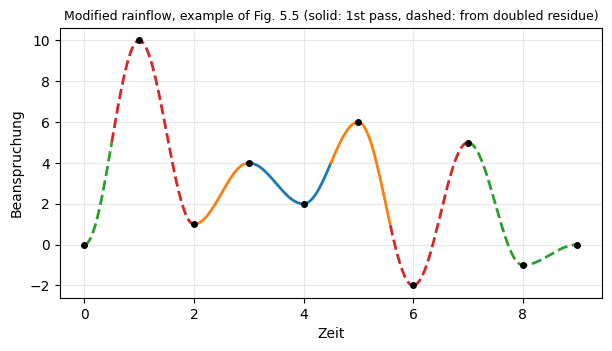

In [2]:
p_ex = np.array([0, 10, 1, 4, 2, 6, -2, 5, -1, 0], float)
t_ex = sample_times(len(p_ex) - 1, n_per=200, extra=0.0)
y_ex, _ = cosine_interp(p_ex, t_ex)
rf = ModifiedRainflow(t_ex, y_ex).run()

rows = []
for c in range(rf.n_cycles):
    iv = [(round(a, 3), round(b, 3)) for a, b, k in zip(rf.a, rf.b, rf.cid) if k == c]
    rows.append(dict(cycle=c, p_from=rf.p_from[c], p_to=rf.p_to[c], amplitude=abs(rf.p_from[c] - rf.p_to[c]) / 2,
                     **{'pass': rf.pass_id[c]}, intervals=iv))
display(pd.DataFrame(rows))
print('Residue after first pass:', [round(v, 3) for v, _ in rf.residue_points])

# checks: same cycles as the standard count; first pass + residue cover [0, T] exactly once
std, res = rainflow_values(p_ex)
assert Counter((round(a, 9), round(b, 9)) for a, b in std) == Counter((round(a, 9), round(b, 9)) for a, b in zip(rf.p_from, rf.p_to))
first = rf.pass_id[rf.cid] == 1
cover = np.sum(rf.b[first] - rf.a[first]) + sum(e - s for s, e in rf.residue_intervals)
assert abs(cover - t_ex[-1]) < 1e-9
# expected from Fig. 5.5 (first pass): cycle (4, 2) inside cycle (1, 6)
assert [(rf.p_from[i], rf.p_to[i]) for i in range(rf.n_cycles) if rf.pass_id[i] == 1] == [(4.0, 2.0), (1.0, 6.0)]
print('Fig. 5.5 example: OK')

fig, ax = plt.subplots(figsize=(7, 3.5))
cols = plt.cm.tab10.colors
for c in range(rf.n_cycles):
    for a, b, k in zip(rf.a, rf.b, rf.cid):
        if k == c:
            m = (t_ex >= a) & (t_ex <= b)
            ax.plot(t_ex[m], y_ex[m], color=cols[c], lw=2, ls='-' if rf.pass_id[c] == 1 else '--')
ax.plot(np.arange(len(p_ex)), p_ex, 'ko', ms=4)
ax.set_xlabel('Zeit'); ax.set_ylabel('Beanspruchung'); ax.grid(alpha=0.3)
ax.set_title('Modified rainflow, example of Fig. 5.5 (solid: 1st pass, dashed: from doubled residue)', fontsize=9)
plt.show()

### Random sequences: modified ≡ standard rainflow (cycles), intervals cover the signal

In [3]:
rng = np.random.default_rng(42)
for trial in range(40):
    p = np.concatenate([[0.0], rng.normal(size=300), [0.0]])
    if trial >= 20:
        p = np.round(p * 4) / 4   # many equal values (ties), as produced by classified amplitudes
    t = sample_times(len(p) - 1, n_per=8, extra=0.0)
    y, _ = cosine_interp(p, t)
    rfm = ModifiedRainflow(t, y).run()
    std, _ = rainflow_values(p)
    key = lambda a, b: (round(a, 9), round(b, 9))
    assert Counter(key(a, b) for a, b in std) == Counter(key(a, b) for a, b in zip(rfm.p_from, rfm.p_to)), trial
    first = rfm.pass_id[rfm.cid] == 1
    cover = np.sum(rfm.b[first] - rfm.a[first]) + sum(e - s for s, e in rfm.residue_intervals)
    assert abs(cover - t[-1]) < 1e-8
print('40 random sequences (20 with ties): modified rainflow == standard rainflow, interval coverage exact: OK')

# excerpt of the classified Gauss sequence (many equal amplitudes)
p = gauss_reversals(L_TF, seed=1, n_classes=32)[:4001].copy(); p[-1] = 0.0
t = sample_times(len(p) - 1, n_per=16, extra=0.0)
y, _ = cosine_interp(p, t)
rfm = ModifiedRainflow(t, y).run()
assert rfm.n_cycles == len(rainflow_values(p)[0]), (rfm.n_cycles, len(rainflow_values(p)[0]))
print('Gauss sequence excerpt (ties): cycle count modified == standard:', rfm.n_cycles)

40 random sequences (20 with ties): modified rainflow == standard rainflow, interval coverage exact: OK
Gauss sequence excerpt (ties): cycle count modified == standard: 2000


## 2. Synthetic Gauss sequence (Sec. 3.4)
Cumulative spectrum $H(x) = L_{TF}^{\,1-x^2}$ with $x = L_a/L_{a,max}$. Amplitudes are set to the upper limits of 32 classes,
because the staircase in Fig. 3.10 has a step height of about 1/32.
All cycles are nested in one enclosing half cycle −1 → +1, as symmetric excursions $(+x_i, -x_i)$ in random order (seed 1).

reversal points: 100882  rainflow cycles: 50440  (L_TF = 50441 )
Rainflow reproduces the prescribed spectrum exactly: OK


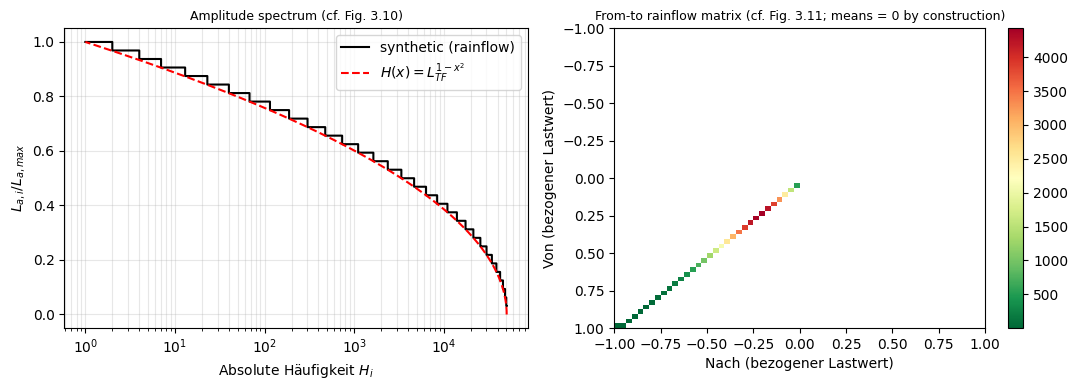

In [4]:
p_g = gauss_reversals(L_TF, seed=1, n_classes=32)
cyc, res = rainflow_values(p_g)
amps = np.array([abs(a - b) / 2 for a, b in cyc])
means = np.array([(a + b) / 2 for a, b in cyc])
target = np.sort(np.concatenate([[1.0], np.ceil(gauss_amplitudes(L_TF)[1:] * 32) / 32]))[::-1]
print('reversal points:', len(p_g), ' rainflow cycles:', len(cyc), ' (L_TF =', L_TF, ')')
assert np.allclose(np.sort(amps)[::-1], target), 'rainflow must reproduce the prescribed amplitudes exactly'
print('Rainflow reproduces the prescribed spectrum exactly: OK')

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
H = np.arange(1, len(amps) + 1)
axs[0].semilogx(H, np.sort(amps)[::-1], 'k-', drawstyle='steps-post', label='synthetic (rainflow)')
xx = np.linspace(0, 1, 200)
axs[0].semilogx(L_TF ** (1 - xx ** 2), xx, 'r--', label=r'$H(x)=L_{TF}^{1-x^2}$')
axs[0].set_xlabel('Absolute Häufigkeit $H_i$'); axs[0].set_ylabel(r'$L_{a,i}/L_{a,max}$')
axs[0].set_title('Amplitude spectrum (cf. Fig. 3.10)', fontsize=9); axs[0].legend(); axs[0].grid(alpha=0.3, which='both')
fr = np.array([a for a, b in cyc]); to = np.array([b for a, b in cyc])
hm = axs[1].hist2d(to, fr, bins=64, range=[[-1, 1], [-1, 1]], cmap='RdYlGn_r', cmin=1)
axs[1].invert_yaxis(); plt.colorbar(hm[3], ax=axs[1])
axs[1].set_xlabel('Nach (bezogener Lastwert)'); axs[1].set_ylabel('Von (bezogener Lastwert)')
axs[1].set_title('From-to rainflow matrix (cf. Fig. 3.11; means = 0 by construction)', fontsize=9)
plt.tight_layout(); plt.show()

### Validation: damage sums $D_{TF}$ of Tab. 3.14 (joint evaluation, normed S-N curves Tab. 3.8)
Palmgren-Miner modified by Haibach, $k' = 2k-2$ (Sec. 3.6, Eqs. (3.8)–(3.10)): $D_{TF} = \sum_i 1/N(L_i)$, $D_{tat} = \bar N_{exp}/L_{TF}\cdot D_{TF}$.

In [5]:
wl = P['woehler_normed_tab_3_8']
tab314 = [('ax', 4.5, 4.50e5, 0.0647, 0.58), ('ax', 2.5, 4.73e6, 0.0079, 0.74),
          ('tors', 196, 5.28e5, 0.0903, 0.53), ('tors', 140, 3.98e6, 0.0084, 0.66),
          ('d0', 4.5, 3.64e5, 0.1104, 0.80), ('d0', 3.0, 2.76e6, 0.0183, 1.00),
          ('d90', 3.0, 5.90e5, 0.0464, 0.54), ('d90', 2.0, 4.48e6, 0.0066, 0.58)]
rows = []
for variant, a_used in (('32 classes (default)', amps),
                        ('continuous', np.sort(gauss_amplitudes(L_TF))[::-1])):
    for lc, L, Nexp, D_ref, Dtat_ref in tab314:
        w = wl[lc]
        sn = SN(w['k'], w['L_k'], w['N_k'], haibach(w['k'], P['haibach_m']))
        D = float(np.sum(1.0 / sn.N(L * a_used)))
        rows.append(dict(variant=variant, loadcase=lc, L=L, D_TF=D, D_TF_tab=D_ref, ratio=D / D_ref,
                         D_tat=Nexp / L_TF * D, D_tat_tab=Dtat_ref))
dtf = pd.DataFrame(rows)
display(dtf.round(4))
print('median ratio D_TF/D_TF,tab (32 classes):', dtf[dtf.variant.str.startswith('32')].ratio.median().round(3))
print('Note: torsion 196 Nm deviates by a factor of ~2 in all variants (compare AZ61 224 Nm in Tab. 3.13: 0.0388).')

,variant,loadcase,L,D_TF,D_TF_tab,ratio,D_tat,D_tat_tab
0,32 classes (default),ax,4.5,0.0621,0.0647,0.9602,0.5542,0.58
1,32 classes (default),ax,2.5,0.0074,0.0079,0.9420,0.6978,0.74
2,32 classes (default),tors,196.0,0.0463,0.0903,0.5125,0.4845,0.53
3,32 classes (default),tors,140.0,0.0076,0.0084,0.9024,0.5981,0.66
4,32 classes (default),d0,4.5,0.1038,0.1104,0.9398,0.7487,0.80
5,32 classes (default),d0,3.0,0.0169,0.0183,0.9230,0.9243,1.00
6,32 classes (default),d90,3.0,0.0433,0.0464,0.9333,0.5065,0.54
7,32 classes (default),d90,2.0,0.0060,0.0066,0.9042,0.5300,0.58
8,continuous,ax,4.5,0.0548,0.0647,0.8477,0.4893,0.58
9,continuous,ax,2.5,0.0065,0.0079,0.8217,0.6088,0.74


median ratio D_TF/D_TF,tab (32 classes): 0.928
Note: torsion 196 Nm deviates by a factor of ~2 in all variants (compare AZ61 224 Nm in Tab. 3.13: 0.0388).


## 3. Two-channel local stresses, δ = 90°
$\sigma_x = c_x \bar F f(t)$, $\sigma_y = c_y \bar F f(t)$, $\tau_{xy} = c_{xy}\bar M_t f(t-\tfrac12)$, inner root notch (Tab. 6.1).

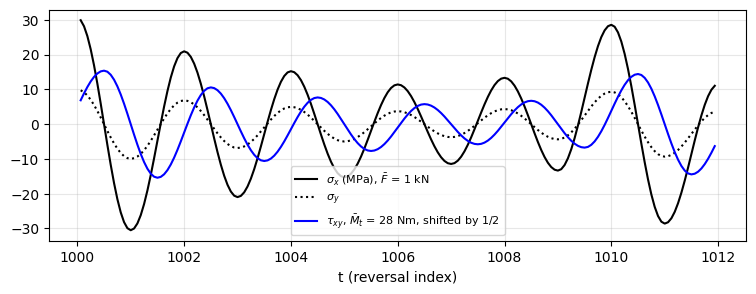

samples: 1614105


In [6]:
tf = P['transfer_factors_tab_6_1']['inner']
t, X, dX = local_channels(p_g, 1.0, P['Mt_over_F'], tf['c_x'], tf['c_y'], tf['c_xy'], shift=0.5, n_per=16)
w = (t > 1000) & (t < 1012)
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(t[w], X[w, 0], 'k-', label=r'$\sigma_x$ (MPa), $\bar F$ = 1 kN')
ax.plot(t[w], X[w, 2], 'k:', label=r'$\sigma_y$')
ax.plot(t[w], X[w, 1], 'b-', label=r'$\tau_{xy}$, $\bar M_t$ = 28 Nm, shifted by 1/2')
ax.set_xlabel('t (reversal index)'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.show()
print('samples:', len(t))